# L6 persistent chains and transverse-field curriculum

Finite diagnostic study: two fixed disorders, both seeds, three arms, 24 stints
per context. Four independent 1,024-walker training islands and 16 negative
temperatures are shared. Each arm receives 24,000 likelihood updates and a shared
Gamma=4 VMC400 initial checkpoint. Direct reset vs direct PCD isolates persistence
between stints. Curriculum PCD changes the field history. It receives only six
target-field stints; direct arms receive 24. Propagation costs differ.

The curriculum uses two stints at each of 4, 3, 2, 1.5, 1.2, 1, .85, .75, .65,
then six at .6. The high starting field is heuristic. At every stint, fresh
populations equilibrate before new training samples are collected. PCD carries
the entire negative ladder and RNG, alongside the guide and optimizer.

Independent Gamma=.6 measurements follow stints 21 and 24: four populations of
512 walkers, equilibration 16, forward time 16, eight cycles, two repeats.
Raw tags and descendant counts independently reconstruct P(q), q2, connected
spectra, energy and genealogy. All contexts and ancestry alarms are retained.

## Research basis

- [Tieleman (2008), PCD](https://www.cs.toronto.edu/~tijmen/pcd/pcd.pdf): persistent
  chains track an evolving model when parameter changes are sufficiently small.
- [Desjardins et al. (2010)](https://proceedings.mlr.press/v9/desjardins10a.html):
  plain Gibbs chains can miss RBM modes; tempering can improve learning and sampling.
- [Pilati, Inack and Pieri (2019)](https://arxiv.org/abs/1907.00907): fit the mixed
  walker density and use its square root as the next guide. Their ferromagnetic
  chain used 10,000 walkers, 20–50 stints and 50,000–100,000 updates per stint;
  this experiment uses a substantially smaller budget and a different model.
- [Brodoloni and Pilati (2024)](https://arxiv.org/abs/2407.05978): self-learned
  guides support frustrated EA simulations after explicit population/ansatz checks.
  Their zero-longitudinal-field square lattice differs from this kagome model.

PCD and curriculum are hypotheses for this problem. Temperature round trips,
unique samples, better energy or a completed run do not establish equilibrium.
The ideal log-amplitude error-halving argument applies at fixed Hamiltonian
and exact fitting/projection; field changes introduce a moving target.
Population, propagation-time, start and training saturation remain unresolved.
Two repeats provide descriptive comparisons, not a reliable systematic-error bound.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
report = json.loads("{\"updated_utc\": \"2026-11-03T16:28:09.343877+00:00\", \"training\": [{\"arm\": \"fixture\", \"context\": \"synthetic\", \"stint\": 0, \"gamma\": 4.0, \"mixed_energy_per_site\": -4.0, \"minimum_training_lineage_ess\": 10.0, \"largest_training_lineage\": 0.2, \"negative_carried\": false, \"rejected_steps\": 0}], \"measurements\": [{\"arm\": \"fixture\", \"task\": {\"sample_id\": 60000, \"seed\": 0}, \"stints\": 24, \"measurements\": [{\"task\": {\"repeat\": 0}, \"energy\": -108.0, \"q2\": 0.5, \"minimum_descendant_ess\": 2.0, \"largest_lineage\": 0.8, \"ancestry_alarm\": true, \"verification\": {\"reconstructed\": true}, \"q_grid\": [-1.0, 0.0, 1.0], \"mass\": [0.25, 0.5, 0.25], \"spectrum\": [1.0, 2.0, 3.0]}, {\"task\": {\"repeat\": 1}, \"energy\": -108.0, \"q2\": 0.5, \"minimum_descendant_ess\": 2.0, \"largest_lineage\": 0.8, \"ancestry_alarm\": true, \"verification\": {\"reconstructed\": true}, \"q_grid\": [-1.0, 0.0, 1.0], \"mass\": [0.25, 0.5, 0.25], \"spectrum\": [1.0, 2.0, 3.0]}]}], \"comparisons\": [{\"kind\": \"repeat\", \"ancestry_alarm\": true}], \"ground_state_qualified\": false, \"limitations\": \"SYNTHETIC DISPLAY FIXTURE ONLY. Matched update count, not identical propagation cost; curriculum spends 18 stints at higher fields. No ancestry-based selection. A high starting field is chosen heuristically; paramagnetic phase is not proved. PCD persistence does not ensure barrier crossing. Population/time/start convergence remains required.\"}")
status = json.loads("{}")
validation = json.loads("{}")
print("Snapshot UTC:", report["updated_utc"])
print("Status:", status)
print("Validation:", {k: validation.get(k) for k in ["passed", "tests", "skipped", "gpu"]})
print("Training stints:", len(report["training"]), "/ 288")
print("Physical measurements:", sum(len(r["measurements"]) for r in report["measurements"]), "/ 48")

Snapshot UTC: 2026-11-03T16:28:09.343877+00:00
Status: {}
Validation: {'passed': None, 'tests': None, 'skipped': None, 'gpu': None}
Training stints: 1 / 288
Physical measurements: 2 / 48


## Adaptation diagnostics
Energy at different fields is not directly comparable. Training ESS is genealogy, not a convergence certificate.

,arm,context,stint,gamma,mixed_energy_per_site,minimum_training_lineage_ess,largest_training_lineage,negative_carried,rejected_steps
0,fixture,synthetic,0,4.0,-4.0,10.0,0.2,False,0


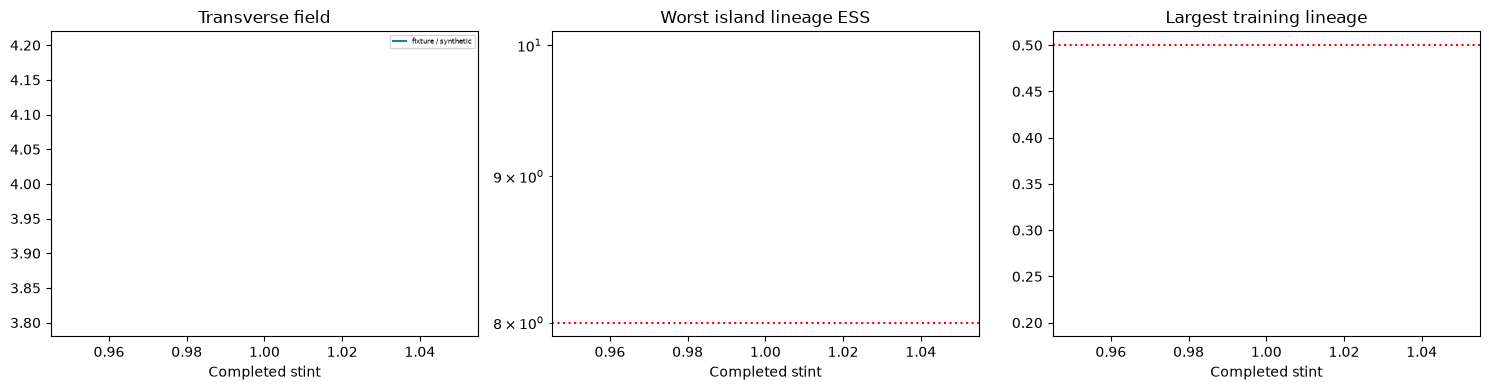

In [2]:
training = pd.DataFrame(report["training"])
if not training.empty:
    display(training[["arm", "context", "stint", "gamma", "mixed_energy_per_site", "minimum_training_lineage_ess", "largest_training_lineage", "negative_carried", "rejected_steps"]])
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for (arm, context), rows in training.groupby(["arm", "context"]):
        rows = rows.sort_values("stint")
        label = arm+" / "+context
        axes[0].plot(rows.stint+1, rows.gamma, label=label)
        axes[1].plot(rows.stint+1, rows.minimum_training_lineage_ess)
        axes[2].plot(rows.stint+1, rows.largest_training_lineage)
    for ax, title in zip(axes, ["Transverse field", "Worst island lineage ESS", "Largest training lineage"]):
        ax.set(xlabel="Completed stint", title=title)
    axes[1].axhline(8, color="red", ls=":"); axes[1].set_yscale("log")
    axes[2].axhline(.5, color="red", ls=":")
    axes[0].legend(fontsize=5); fig.tight_layout(); plt.show()
else:
    print("Training has not completed its first stint.")

## Independent physical measurements and comparisons
Every result includes raw reconstruction verification. Alarmed measurements remain visible.

,arm,sample_id,seed,stints,repeat,energy_per_site,q2,minimum_descendant_ess,largest_lineage,ancestry_alarm,reconstructed
0,fixture,60000,0,24,0,-1.0,0.5,2.0,0.8,True,True
1,fixture,60000,0,24,1,-1.0,0.5,2.0,0.8,True,True


,kind,ancestry_alarm
0,repeat,True


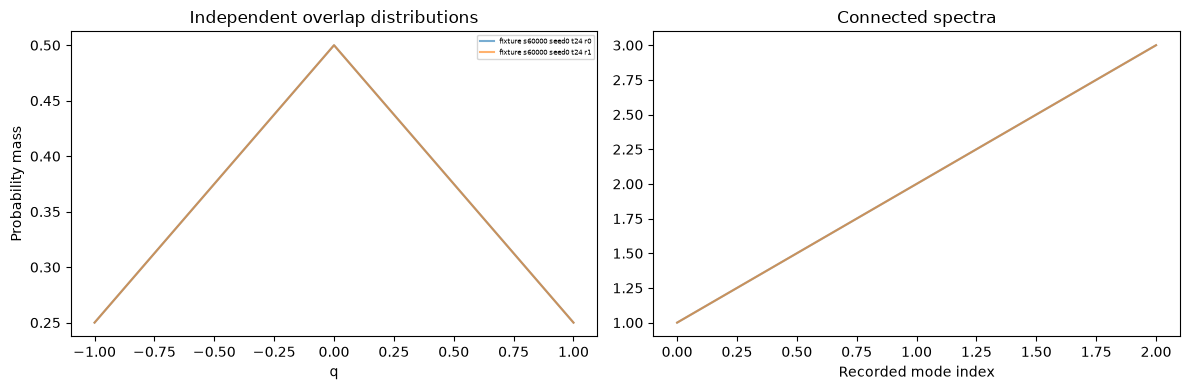

SYNTHETIC DISPLAY FIXTURE ONLY. Matched update count, not identical propagation cost; curriculum spends 18 stints at higher fields. No ancestry-based selection. A high starting field is chosen heuristically; paramagnetic phase is not proved. PCD persistence does not ensure barrier crossing. Population/time/start convergence remains required.


In [3]:
physical = []
for group in report["measurements"]:
    for m in group["measurements"]:
        physical.append(dict(arm=group["arm"], sample_id=group["task"]["sample_id"], seed=group["task"]["seed"], stints=group["stints"], repeat=m["task"]["repeat"], energy_per_site=m["energy"]/108, q2=m["q2"], minimum_descendant_ess=m["minimum_descendant_ess"], largest_lineage=m["largest_lineage"], ancestry_alarm=m["ancestry_alarm"], reconstructed=m["verification"]["reconstructed"]))
display(pd.DataFrame(physical))
display(pd.DataFrame(report["comparisons"]))
if physical:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for group in report["measurements"]:
        for m in group["measurements"]:
            label = f"{group['arm']} s{group['task']['sample_id']} seed{group['task']['seed']} t{group['stints']} r{m['task']['repeat']}"
            axes[0].plot(m["q_grid"], m["mass"], label=label, alpha=.6)
            axes[1].plot(m["spectrum"], alpha=.6)
    axes[0].set(xlabel="q", ylabel="Probability mass", title="Independent overlap distributions")
    axes[1].set(xlabel="Recorded mode index", title="Connected spectra")
    axes[0].legend(fontsize=5); fig.tight_layout(); plt.show()
else:
    print("Independent target-field measurements are pending.")
print(report["limitations"])
assert report["ground_state_qualified"] is False